## 0. Environment

In [ ]:
import subprocess, sys, os, glob, json, time, shutil, re, textwrap
def sh(cmd, check=True):
    print('$', cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if r.stdout: print(r.stdout[-3000:])
    if r.returncode != 0:
        print(r.stderr[-3000:])
        if check: raise RuntimeError(f'command failed: {cmd}')
    return r

ROOT = os.path.abspath('sr_experiments'); REPOS = os.path.join(ROOT, 'repos')
WEIGHTS = os.path.join(ROOT, 'weights'); OUT = os.path.join(ROOT, 'outputs')
for d in (ROOT, REPOS, WEIGHTS, OUT): os.makedirs(d, exist_ok=True)

sh(f'{sys.executable} -m pip install -q timm einops lpips scikit-image opencv-python-headless pyyaml gdown fvcore '
   'addict future lmdb yapf scipy tqdm requests fairscale')

# BasicSR 1.4.2 no longer builds with recent Python/pip, so it is used from source via PYTHONPATH.
BASICSR = os.path.join(REPOS, 'BasicSR')
if not os.path.isdir(BASICSR):
    sh(f'git clone -q --depth 1 --branch v1.4.2 https://github.com/XPixelGroup/BasicSR.git {BASICSR}')

def prep_basicsr_tree(root):
    # write the version file that setup.py would generate, and fix the torchvision import removed in torchvision 0.17
    for pkg in glob.glob(os.path.join(root, '**', 'basicsr'), recursive=True) + [os.path.join(root, 'basicsr')]:
        if os.path.isdir(pkg) and not os.path.exists(os.path.join(pkg, 'version.py')):
            open(os.path.join(pkg, 'version.py'), 'w').write("__version__ = '1.4.2'\n__gitsha__ = 'unknown'\nversion_info = (1, 4, 2)\n")
    for f in glob.glob(os.path.join(root, '**', '*.py'), recursive=True):
        t = open(f, errors='ignore').read()
        if 'torchvision.transforms.functional_tensor' in t:
            open(f, 'w').write(t.replace('torchvision.transforms.functional_tensor', 'torchvision.transforms.functional'))

prep_basicsr_tree(BASICSR)
# HAT was written for BasicSR 1.3.x, where the colour conversions lived in matlab_functions
mf = os.path.join(BASICSR, 'basicsr', 'utils', 'matlab_functions.py')
if 'compat: colour conversions' not in open(mf).read():
    open(mf, 'a').write('\n# compat: colour conversions moved to color_util in BasicSR 1.4\n'
                        'from basicsr.utils.color_util import rgb2ycbcr, bgr2ycbcr, ycbcr2rgb, ycbcr2bgr  # noqa\n')
sys.path.insert(0, BASICSR)
os.environ['PYTHONPATH'] = BASICSR + ':' + os.environ.get('PYTHONPATH', '')
import torch
print('torch', torch.__version__, '| CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available(): print(torch.cuda.get_device_name(0))

$ /usr/bin/python3 -m pip install -q timm einops lpips scikit-image opencv-python-headless pyyaml gdown fvcore addict future lmdb yapf scipy tqdm requests fairscale
$ git clone -q --depth 1 --branch v1.4.2 https://github.com/XPixelGroup/BasicSR.git /content/sr_experiments/repos/BasicSR
torch 2.14.1+cu130 | CUDA available: True
NVIDIA L4


## 1. Configuration



In [ ]:
URBAN100_HR = '/content/data/Urban100/HR'            # <-- edit
URBAN_IMAGES = ['img_062', 'img_092']
REALSR_IMAGES = ['Canon_026', 'Nikon_031', 'Canon_041']
REALSR_LR_PATTERN = '{name}_LR4.png'
REALSR_HR_PATTERN = '{name}_HR.png'
SCALE = 4

# Outputs you already have for the existing columns: {method: folder}. File names must contain the image name.
EXISTING_OUTPUTS = {
    'fig10': {  # 'SRResNet': '/content/old_outputs/fig10/SRResNet', ...
    },
    'fig11': {  # 'BSRGAN': '/content/old_outputs/fig11/BSRGAN', ...
    },
}

# Enlarged regions in HR coordinates (x, y, w, h). Replace with the boxes used in the current figures.
CROPS = {
    'img_062':  (0, 0, 120, 120),
    'img_092':  (0, 0, 120, 120),
    'Canon_026': (0, 0, 120, 120),
    'Nikon_031': (0, 0, 120, 120),
    'Canon_041': (0, 0, 120, 120),
}


WEIGHT_FILES = {
    'HAT':       'HAT_SRx4.pth',                        # Google Drive folder in the HAT README
    'PFT':       '003_PFT_SRx4_finetune.pth',           # Google Drive folder in the PFT-SR README
    'MambaIR':   'MambaIR_classicSRx4.pth',               # Hugging Face cguoh/MambaIR (MambaIRv1_ckpt/)
    'MambaIRv2': 'mambairv2_classicSR_Base_x4.pth',     # Hugging Face cguoh/MambaIR
}
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

## 2. Code, weights and shared utilities

In [ ]:
REPO_URLS = {
    'HAT': 'https://github.com/XPixelGroup/HAT.git',
    'PFT': 'https://github.com/LabShuHangGU/PFT-SR.git',
    'MambaIR': 'https://github.com/csguoh/MambaIR.git',
}
for name, url in REPO_URLS.items():
    dst = os.path.join(REPOS, name)
    if not os.path.isdir(dst): sh(f'git clone --depth 1 {url} {dst}', check=False)
    if os.path.isdir(dst): prep_basicsr_tree(dst)

# CUDA extension for PFT (sparse matrix multiplication)
# mamba-ssm is NOT pip-installed any more (its build fails on this torch/CUDA); the next cell provides selective_scan_fn instead.
if os.path.isdir(os.path.join(REPOS, 'PFT', 'ops_smm')):
    sh(f'cd {os.path.join(REPOS, "PFT", "ops_smm")} && {sys.executable} setup.py install', check=False)

import gdown
DRIVE_FOLDERS = {'HAT': 'https://drive.google.com/drive/folders/1HpmReFfoUqUbnAOQ7rvOeNU3uf_m69w0',
                 'PFT': 'https://drive.google.com/drive/folders/1ChkxVDghFWUtJydJKLp5yssrUfm0VWfg'}
for k, url in DRIVE_FOLDERS.items():
    dst = os.path.join(WEIGHTS, WEIGHT_FILES[k])
    if os.path.exists(dst): continue
    try:
        tmp = os.path.join(WEIGHTS, f'_drive_{k}')
        gdown.download_folder(url, output=tmp, quiet=True, remaining_ok=True)
        hit = [p for p in glob.glob(os.path.join(tmp, '**', '*'), recursive=True) if os.path.basename(p) == WEIGHT_FILES[k]]
        if hit: shutil.copy(hit[0], dst)
    except Exception as e:
        print(k, 'automatic download failed:', repr(e)[:200])

from huggingface_hub import list_repo_files, hf_hub_download
try:
    files = list_repo_files('cguoh/MambaIR')
    print('cguoh/MambaIR files:', *files, sep='\n  ')
    for k in ('MambaIR', 'MambaIRv2'):
        dst = os.path.join(WEIGHTS, WEIGHT_FILES[k])
        hit = [f for f in files if os.path.basename(f) == WEIGHT_FILES[k]]
        if hit and not os.path.exists(dst): shutil.copy(hf_hub_download('cguoh/MambaIR', hit[0]), dst)
except Exception as e:
    print('Hugging Face download failed:', repr(e)[:200])

for k, f in WEIGHT_FILES.items():
    print(f'{k:10s} {f:38s}', 'present' if os.path.exists(os.path.join(WEIGHTS, f)) else 'MISSING - place it in ' + WEIGHTS)

$ git clone --depth 1 https://github.com/XPixelGroup/HAT.git /content/sr_experiments/repos/HAT
$ git clone --depth 1 https://github.com/LabShuHangGU/PFT-SR.git /content/sr_experiments/repos/PFT
$ git clone --depth 1 https://github.com/csguoh/MambaIR.git /content/sr_experiments/repos/MambaIR
$ cd /content/sr_experiments/repos/PFT/ops_smm && /usr/bin/python3 setup.py install
Building with CUDA architectures: ['-gencode', 'arch=compute_75,code=sm_75', '-gencode', 'arch=compute_80,code=sm_80', '-gencode', 'arch=compute_86,code=sm_86', '-gencode', 'arch=compute_90,code=sm_90', '-gencode', 'arch=compute_100,code=sm_100', '-gencode', 'arch=compute_120,code=sm_120']
running install
running build
running build_ext
building 'smm_cuda' extension
creating build/temp.linux-x86_64-cpython-313/content/sr_experiments/repos/PFT/ops_smm/src
/usr/local/cuda/bin/nvcc -DWITH_CUDA -I/content/sr_experiments/repos/PFT/ops_smm/src -I/usr/local/lib/python3.13/dist-packages/torch/include -I/usr/local/lib/python3

MambaIRv1_ckpt/MambaIR_classicSRx4.pth: reconstructing file:   0%|          |  0.00B / 82.6MB            

MambaIRv1_ckpt/MambaIR_classicSRx4.pth: downloading bytes:           |  0.00B            

MambaIRv2_ckpt/mambairv2_classicSR_Base_(…): reconstructing file:   0%|          |  0.00B / 93.5MB            

MambaIRv2_ckpt/mambairv2_classicSR_Base_(…): downloading bytes:           |  0.00B            

HAT        HAT_SRx4.pth                           present
PFT        003_PFT_SRx4_finetune.pth              present
MambaIR    MambaIR_classicSRx4.pth                present
MambaIRv2  mambairv2_classicSR_Base_x4.pth        present


In [ ]:
# Selective-scan backend for MambaIR / MambaIRv2.

import site, subprocess, textwrap
SHIM_SRC = r"""
import os, torch, torch.nn.functional as F
try:
    import selective_scan_cuda
except Exception:
    selective_scan_cuda = None

def selective_scan_ref(u, delta, A, B, C, D=None, z=None, delta_bias=None, delta_softplus=False,
                       return_last_state=False, chunk=1024):
    # chunked recurrence x_t = exp(delta_t A) x_{t-1} + delta_t B_t u_t, y_t = C_t x_t + D u_t (real A)
    dtype_in = u.dtype
    u = u.float(); delta = delta.float(); A = A.float()
    if delta_bias is not None: delta = delta + delta_bias.float()[..., None]
    if delta_softplus: delta = F.softplus(delta)
    b, d, l = u.shape; n = A.shape[1]
    if B.dim() == 3: B = B[:, None]
    if C.dim() == 3: C = C[:, None]
    g = B.shape[1]; h = d // g
    B = B.float(); C = C.float()
    dl_all = delta.reshape(b, g, h, l); u_all = u.reshape(b, g, h, l); Ag = A.reshape(g, h, n)
    x = u.new_zeros(b, g, h, n); outs = []
    for s in range(0, l, chunk):
        e = min(s + chunk, l); c = e - s
        dl = dl_all[..., s:e]
        dA = torch.exp(torch.einsum('bghc,ghn->bghcn', dl, Ag))
        dBu = torch.einsum('bghc,bgnc,bghc->bghcn', dl, B[..., s:e], u_all[..., s:e])
        xs = torch.empty_like(dBu)
        for i in range(c):
            x = dA[:, :, :, i] * x + dBu[:, :, :, i]
            xs[:, :, :, i] = x
        outs.append(torch.einsum('bghcn,bgnc->bghc', xs, C[..., s:e]))
    out = torch.cat(outs, -1).reshape(b, d, l)
    if D is not None: out = out + u * D.float()[None, :, None]
    if z is not None: out = out * F.silu(z.float())
    out = out.to(dtype_in)
    return (out, x.reshape(b, d, n)) if return_last_state else out

class SelectiveScanFn(torch.autograd.Function):   # class name is what fvcore/MambaIR's FLOP counter looks for
    @staticmethod
    def forward(ctx, u, delta, A, B, C, D=None, z=None, delta_bias=None, delta_softplus=False, return_last_state=False):
        if os.environ.get('MAMBA_SHIM_SHAPE_ONLY') == '1':      # FLOP counting only needs shapes
            out = torch.zeros_like(u); last = u.new_zeros(u.shape[0], u.shape[1], A.shape[1])
        elif selective_scan_cuda is not None and u.is_cuda:
            u = u.contiguous(); delta = delta.contiguous()
            if B.dim() == 3: B = B[:, None]
            if C.dim() == 3: C = C[:, None]
            B = B.contiguous(); C = C.contiguous()
            if D is not None: D = D.contiguous()
            if z is not None: z = z.contiguous()
            out, x, *rest = selective_scan_cuda.fwd(u, delta, A, B, C, D, z, delta_bias, delta_softplus)
            last = x[:, :, -1, 1::2]
            if z is not None: out = rest[0]
        else:
            out, last = selective_scan_ref(u, delta, A, B, C, D, z, delta_bias, delta_softplus, True)
        return (out, last) if return_last_state else out

def selective_scan_fn(u, delta, A, B, C, D=None, z=None, delta_bias=None, delta_softplus=False, return_last_state=False):
    return SelectiveScanFn.apply(u, delta, A, B, C, D, z, delta_bias, delta_softplus, return_last_state)
"""

def install_shim():
    pkg = os.path.join(site.getsitepackages()[0], 'mamba_ssm')
    os.makedirs(os.path.join(pkg, 'ops'), exist_ok=True)
    open(os.path.join(pkg, '__init__.py'), 'w').write('')
    open(os.path.join(pkg, 'ops', '__init__.py'), 'w').write('')
    open(os.path.join(pkg, 'ops', 'selective_scan_interface.py'), 'w').write(SHIM_SRC)

def build_kernel(timeout_min=45):
    mamba = os.path.join(ROOT, 'mamba_src')
    if not os.path.isdir(mamba):
        subprocess.run(f'git clone -q --depth 1 https://github.com/state-spaces/mamba.git {mamba}', shell=True)
    d = os.path.join(mamba, 'csrc', 'selective_scan')
    cap = torch.cuda.get_device_capability(); arch = f'{cap[0]}{cap[1]}'
    open(os.path.join(mamba, 'build_scan.py'), 'w').write(textwrap.dedent(f"""
        import glob, os
        from setuptools import setup
        from torch.utils.cpp_extension import BuildExtension, CUDAExtension
        d = {d!r}
        srcs = sorted(glob.glob(d + '/*.cpp') + glob.glob(d + '/*.cu'))
        nvcc = ['-O3', '-std=c++17', '--expt-relaxed-constexpr', '--expt-extended-lambda', '--use_fast_math', '--threads', '4',
                '-U__CUDA_NO_HALF_OPERATORS__', '-U__CUDA_NO_HALF_CONVERSIONS__', '-U__CUDA_NO_BFLOAT16_OPERATORS__',
                '-U__CUDA_NO_BFLOAT16_CONVERSIONS__', '-U__CUDA_NO_HALF2_OPERATORS__', '-U__CUDA_NO_BFLOAT162_OPERATORS__',
                '-U__CUDA_NO_BFLOAT162_CONVERSIONS__', '-gencode', 'arch=compute_{arch},code=sm_{arch}']
        setup(name='selective_scan_cuda', packages=[], ext_modules=[CUDAExtension('selective_scan_cuda', srcs, include_dirs=[d],
              extra_compile_args={{'cxx': ['-O3', '-std=c++17'], 'nvcc': nvcc}})], cmdclass={{'build_ext': BuildExtension}})
    """))
    log = os.path.join(OUT, 'selective_scan_build.log')
    env = dict(os.environ, MAX_JOBS='4')
    try:
        r = subprocess.run(f'cd {mamba} && {sys.executable} build_scan.py install', shell=True, text=True,
                           capture_output=True, timeout=timeout_min * 60, env=env)
        open(log, 'w').write((r.stdout or '') + '\n' + (r.stderr or ''))
        return r.returncode == 0, log
    except subprocess.TimeoutExpired:
        open(log, 'w').write('build timed out'); return False, log

def check_backend():
    # run in a fresh process so a half-installed extension cannot poison this one
    code = r"""
import torch, sys
from mamba_ssm.ops.selective_scan_interface import selective_scan_fn, selective_scan_ref, SelectiveScanFn
import mamba_ssm.ops.selective_scan_interface as m
torch.manual_seed(0); b, g, h, n, l = 2, 4, 8, 16, 512; d = g * h
u = torch.randn(b, d, l, device='cuda'); dl = torch.randn(b, d, l, device='cuda') * .5
A = -torch.rand(d, n, device='cuda'); B = torch.randn(b, g, n, l, device='cuda'); C = torch.randn(b, g, n, l, device='cuda')
D = torch.randn(d, device='cuda'); bias = torch.randn(d, device='cuda')
y = selective_scan_fn(u, dl, A, B, C, D, None, bias, True)
r = selective_scan_ref(u, dl, A, B, C, D, None, bias, True)
print('kernel_loaded', m.selective_scan_cuda is not None, 'max_abs_err', (y - r).abs().max().item())
"""
    r = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True)
    print(r.stdout.strip() or r.stderr[-1500:])
    ok = 'kernel_loaded True' in r.stdout and float(r.stdout.split('max_abs_err')[1]) < 1e-3
    return ok

MAMBA_BACKEND = 'reference'
if DEVICE == 'cuda':
    ok, log = build_kernel()
    print('selective_scan_cuda build', 'succeeded' if ok else 'FAILED (see ' + log + ')')
    if not ok: print(open(log).read()[-1500:])
    install_shim()
    if ok and check_backend(): MAMBA_BACKEND = 'cuda'
else:
    install_shim()
print('MAMBA_BACKEND =', MAMBA_BACKEND)
if MAMBA_BACKEND == 'reference':
    print('Reference scan in use: MambaIR/MambaIRv2 images and FLOPs are valid; latency and peak memory are not reported for them.')


selective_scan_cuda build FAILED (see /content/sr_experiments/outputs/selective_scan_build.log)
ore/jit_type.h:90:13: note: candidate: ‘bool c10::operator!=(const Type&, const Type&)’
   90 | inline bool operator!=(const Type& lhs, const Type& rhs) {
      |             ^~~~~~~~
/usr/local/lib/python3.13/dist-packages/torch/include/ATen/core/jit_type.h:90:36: note:   no known conversion for argument 1 from ‘const c10::intrusive_ptr<torch::autograd::Node>’ to ‘const c10::Type&’
   90 | inline bool operator!=(const Type& lhs, const Type& rhs) {
      |                        ~~~~~~~~~~~~^~~
In file included from /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/autograd/input_metadata.h:4,
                 from /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/autograd/node.h:8,
                 from /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/autograd/variable.h:11:
/usr/local/lib/python3.13/dist-packages/torch/include/ATen/ExpandUtils.

In [ ]:
import numpy as np, cv2, torch, lpips
from skimage.metrics import structural_similarity

def imread(p):  # RGB uint8
    im = cv2.imread(p, cv2.IMREAD_COLOR)
    if im is None: raise FileNotFoundError(p)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

def imwrite(p, im):
    os.makedirs(os.path.dirname(p), exist_ok=True)
    cv2.imwrite(p, cv2.cvtColor(im, cv2.COLOR_RGB2BGR))

def rgb2y(im):
    # ITU-R BT.601 luma used by MATLAB rgb2ycbcr and BasicSR (range 16-235)
    im = im.astype(np.float64) / 255.
    return 16. + 65.481 * im[..., 0] + 128.553 * im[..., 1] + 24.966 * im[..., 2]

def mod_crop(im, s=SCALE):
    h, w = im.shape[:2]; return im[:h - h % s, :w - w % s]

def psnr_y(sr, hr, border=SCALE):
    a, b = rgb2y(sr), rgb2y(hr)
    if border: a, b = a[border:-border, border:-border], b[border:-border, border:-border]
    mse = np.mean((a - b) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255. ** 2 / mse)

def ssim_y(sr, hr, border=SCALE):
    a, b = rgb2y(sr), rgb2y(hr)
    if border: a, b = a[border:-border, border:-border], b[border:-border, border:-border]
    # Gaussian window sigma 1.5, as in the original SSIM implementation
    return float(structural_similarity(a, b, data_range=255, gaussian_weights=True, sigma=1.5, use_sample_covariance=False))

_lpips = None
def lpips_rgb(sr, hr):
    global _lpips
    if _lpips is None: _lpips = lpips.LPIPS(net='alex', verbose=False).to(DEVICE).eval()
    t = lambda x: torch.from_numpy(x).permute(2, 0, 1)[None].float().div(127.5).sub(1).to(DEVICE)
    with torch.no_grad(): return float(_lpips(t(sr), t(hr)).item())

def crop(im, box):
    x, y, w, h = box; return im[y:y + h, x:x + w]

def bicubic_down_matlab(hr, s=SCALE):
    # MATLAB-compatible bicubic downsampling with antialiasing, as used to create the Urban100 LR images
    from basicsr.utils.matlab_functions import imresize
    return np.clip(np.round(imresize(hr.astype(np.float64) / 255., 1 / s) * 255.), 0, 255).astype(np.uint8)

def bicubic_up(lr, s=SCALE):
    from basicsr.utils.matlab_functions import imresize
    return np.clip(np.round(imresize(lr.astype(np.float64) / 255., s) * 255.), 0, 255).astype(np.uint8)

def find_output(folder, name):
    c = [p for p in glob.glob(os.path.join(folder, '**', '*'), recursive=True)
         if name in os.path.basename(p) and p.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]
    if not c: raise FileNotFoundError(f'{name} not found in {folder}')
    return sorted(c, key=len)[0]
print('utilities ready')

utilities ready


### BasicSR-style runner for HAT, PFT and MambaIR



In [ ]:
import site, importlib

def ensure_fairscale():
    try:
        importlib.import_module('fairscale.nn'); return
    except Exception: pass
    sh(f'{sys.executable} -m pip install -q fairscale', check=False)
    try:
        importlib.invalidate_caches(); importlib.import_module('fairscale.nn'); return
    except Exception: pass
    pkg = os.path.join(site.getsitepackages()[0], 'fairscale'); os.makedirs(os.path.join(pkg, 'nn'), exist_ok=True)
    open(os.path.join(pkg, '__init__.py'), 'w').write('')
    open(os.path.join(pkg, 'nn', '__init__.py'), 'w').write('def checkpoint_wrapper(module, *a, **k):\n    return module\n')
    print('fairscale could not be installed; wrote a no-op stub (PFT does not use checkpoint_wrapper)')

import yaml

def find_file(repo, patterns):
    hits = []
    for pat in patterns: hits += glob.glob(os.path.join(REPOS, repo, pat), recursive=True)
    return sorted(set(hits))

def run_basicsr(repo, option_patterns, weight_path, lq_dir, gt_dir, tag, extra_pythonpath=''):
    if repo == 'PFT': ensure_fairscale()
    opts = find_file(repo, option_patterns)
    if not opts: raise FileNotFoundError(f'no option file for {repo}: {option_patterns}')
    print('option files found:', *opts, sep='\n  ')
    opt = yaml.safe_load(open(opts[0]))
    print('using', opts[0], '| network:', opt['network_g'].get('type'))
    opt['name'] = f'review_{tag}'
    opt['num_gpu'] = 1 if DEVICE == 'cuda' else 0
    opt['datasets'] = {'test_1': {'name': tag, 'type': 'PairedImageDataset', 'dataroot_gt': gt_dir, 'dataroot_lq': lq_dir,
                                   'io_backend': {'type': 'disk'}, 'filename_tmpl': '{}'}}
    opt['path'] = {'pretrain_network_g': weight_path, 'strict_load_g': True, 'param_key_g': 'params_ema'}
    opt.setdefault('val', {})['save_img'] = True
    opt['val'].pop('metrics', None)   # metrics are computed below with one shared implementation
    ymlp = os.path.join(ROOT, f'opt_{tag}.yml'); yaml.safe_dump(opt, open(ymlp, 'w'))
    test_py = find_file(repo, ['hat/test.py', 'basicsr/test.py'])[0]
    env = f'PYTHONPATH={os.path.join(REPOS, repo)}:{extra_pythonpath}{BASICSR}'
    r = sh(f'cd {os.path.join(REPOS, repo)} && {env} {sys.executable} {test_py} -opt {ymlp}', check=False)
    if r.returncode != 0 and 'params_ema' in (r.stderr or ''):
        opt['path']['param_key_g'] = 'params'; yaml.safe_dump(opt, open(ymlp, 'w'))
        r = sh(f'cd {os.path.join(REPOS, repo)} && {env} {sys.executable} {test_py} -opt {ymlp}')
    res = glob.glob(os.path.join(REPOS, repo, 'results', f'review_{tag}', 'visualization', '**', '*.png'), recursive=True)
    dst = os.path.join(OUT, tag); os.makedirs(dst, exist_ok=True)
    for p in res: shutil.copy(p, dst)
    print(f'{len(res)} outputs copied to {dst}')
    if not res:
        raise RuntimeError(f'{tag}: the test run produced no images. Last output:\n' + ((r.stdout or '')[-1500:]) + '\n' + ((r.stderr or '')[-2500:]))
    return dst

## 3. Fig. 10: HAT, PFT and MambaIR on Urban100 (comments 62 and 77)

In [ ]:
# ===== Dataset setup: Urban100 (Fig. 10) and RealSR (Fig. 11). Run once; no manual upload needed unless a download fails. =====
import os, glob, shutil, zipfile, tarfile, subprocess, urllib.request

# ---------- 1) Urban100: img_062 and img_092 from the public SelfExSR repository (GitHub) ----------
URBAN100_HR = '/content/data/Urban100/HR'
os.makedirs(URBAN100_HR, exist_ok=True)
URBAN_URL = 'https://raw.githubusercontent.com/jbhuang0604/SelfExSR/master/data/Urban100/image_SRF_4/{}_SRF_4_HR.png'
for n in ['img_062', 'img_092']:
    dst = os.path.join(URBAN100_HR, n + '.png')
    if not (os.path.exists(dst) and os.path.getsize(dst) > 100_000):
        urllib.request.urlretrieve(URBAN_URL.format(n), dst)
    print('Urban100', n, os.path.getsize(dst), 'bytes')

# ---------- 2) RealSR Version 2 (Google Drive id from the official README): Canon_026, Nikon_031, Canon_041 ----------
REALSR_DIR = '/content/data/RealSR'
REALSR_SEL = os.path.join(REALSR_DIR, 'selected')          # {name}_HR.png and {name}_LR4.png end up here
REALSR_NAMES = ['Canon_026', 'Nikon_031', 'Canon_041']
REALSR_GDRIVE_ID = '1dEBRo_1HH6Yk9zrchEg_JTRi-Uhmd-sj'
RAW = os.path.join(REALSR_DIR, 'download'); ARCHIVE = os.path.join(RAW, 'RealSR_v2'); EXTRACT = os.path.join(REALSR_DIR, 'extracted')
os.makedirs(REALSR_SEL, exist_ok=True); os.makedirs(RAW, exist_ok=True)

def _have_all():
    return all(os.path.exists(os.path.join(REALSR_SEL, f'{n}_{s}.png')) for n in REALSR_NAMES for s in ('HR', 'LR4'))

def _run(cmd):
    r = subprocess.run(cmd, text=True, capture_output=True)
    if r.returncode != 0: print('  ', ' '.join(cmd[:3]), '->', (r.stderr or r.stdout)[-300:].strip())
    return r

def _tool(*names):
    for n in names:
        if shutil.which(n): return shutil.which(n)
    return None

def extract_needed(archive, out_dir):
    """Extract only the six needed files from the (6 GB) archive; handles zip, tar, rar and 7z by file signature."""
    os.makedirs(out_dir, exist_ok=True)
    with open(archive, 'rb') as f: sig = f.read(8)
    files = [f'{n}_{s}.png' for n in REALSR_NAMES for s in ('HR', 'LR4')]
    print('archive signature:', sig)
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:
            for m in z.namelist():
                if os.path.basename(m) in files: z.extract(m, out_dir)
    elif tarfile.is_tarfile(archive):
        with tarfile.open(archive) as t:
            for m in t.getmembers():
                if os.path.basename(m.name) in files: t.extract(m, out_dir)
    elif sig.startswith(b'Rar!'):
        if not _tool('unrar'): _run(['bash', '-c', 'apt-get -qq update && apt-get -qq install -y unrar'])
        if _tool('unrar'):
            listing = _run(['unrar', 'lb', archive]).stdout.splitlines()
            for m in [l for l in listing if os.path.basename(l.strip()) in files]:
                _run(['unrar', 'x', '-o+', '-y', archive, m.strip(), out_dir + '/'])
        else:
            if not _tool('7z', '7zz'): _run(['bash', '-c', 'apt-get -qq install -y p7zip-full'])
            sz = _tool('7z', '7zz')
            if sz: _run([sz, 'x', '-y', '-r', f'-o{out_dir}', archive] + [f'*{f}' for f in files])
            else: print('  neither unrar nor 7z could be installed')
    elif sig.startswith(b'7z\xbc\xaf'):
        if not _tool('7z', '7zz'): _run(['bash', '-c', 'apt-get -qq update && apt-get -qq install -y p7zip-full'])
        sz = _tool('7z', '7zz')
        if sz: _run([sz, 'x', '-y', '-r', f'-o{out_dir}', archive] + [f'*{f}' for f in files])
    else:
        print('  unknown archive type; the first bytes are shown above')

if not _have_all():
    try:
        if not (os.path.exists(ARCHIVE) and os.path.getsize(ARCHIVE) > 10**9):      # skip the 6 GB download if already there
            import gdown
            out = gdown.download(id=REALSR_GDRIVE_ID, output=ARCHIVE, quiet=False)
            if out is None: raise RuntimeError('gdown returned nothing (quota or permission)')
        extract_needed(ARCHIVE, EXTRACT)
        for n in REALSR_NAMES:
            for s in ('HR', 'LR4'):
                hits = glob.glob(os.path.join(EXTRACT, '**', f'{n}_{s}.png'), recursive=True)
                hits.sort(key=lambda p: ('test' not in p.lower(), len(p)))        # prefer the Test split
                if hits: shutil.copy(hits[0], os.path.join(REALSR_SEL, f'{n}_{s}.png'))
    except Exception as e:
        print('RealSR step failed:', repr(e)[:200])

for n in REALSR_NAMES:
    for s in ('HR', 'LR4'):
        p = os.path.join(REALSR_SEL, f'{n}_{s}.png')
        print('RealSR', f'{n}_{s}.png', 'OK' if os.path.exists(p) else 'MISSING')
if not _have_all():
    print('\nSome RealSR files are missing. Fig. 10 does not need them. Send the "archive signature" line above if extraction failed.')


Urban100 img_062 1206947 bytes
Urban100 img_092 1493427 bytes


Downloading...
From (original): https://drive.google.com/uc?id=1dEBRo_1HH6Yk9zrchEg_JTRi-Uhmd-sj
From (redirected): https://drive.google.com/uc?id=1dEBRo_1HH6Yk9zrchEg_JTRi-Uhmd-sj&confirm=t&uuid=07440383-25df-471a-85cd-9ef8c4c82708
To: /content/data/RealSR/download/RealSR_v2
100%|██████████| 6.29G/6.29G [01:43<00:00, 60.8MB/s]


archive signature: b'\x1f\x8b\x08\x00W\x00D]'


/tmp/ipykernel_1922/3729689983.py:48: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  if os.path.basename(m.name) in files: t.extract(m, out_dir)


RealSR Canon_026_HR.png OK
RealSR Canon_026_LR4.png OK
RealSR Nikon_031_HR.png OK
RealSR Nikon_031_LR4.png OK
RealSR Canon_041_HR.png OK
RealSR Canon_041_LR4.png OK


In [ ]:
# Prepare paired data: HR mod-cropped to a multiple of 4, LR by MATLAB bicubic (the standard Urban100 protocol)
U_HR = os.path.join(ROOT, 'urban_hr'); U_LR = os.path.join(ROOT, 'urban_lr')
os.makedirs(U_HR, exist_ok=True); os.makedirs(U_LR, exist_ok=True)
for n in URBAN_IMAGES:
    hr = mod_crop(imread(os.path.join(URBAN100_HR, n + '.png')))
    imwrite(os.path.join(U_HR, n + '.png'), hr)
    imwrite(os.path.join(U_LR, n + '.png'), bicubic_down_matlab(hr))
print(os.listdir(U_LR))

['img_062.png', 'img_092.png']


In [ ]:
fig10_new = {}
fig10_new['HAT'] = run_basicsr('HAT', ['options/test/HAT_SRx4.yml'],
                               os.path.join(WEIGHTS, WEIGHT_FILES['HAT']), U_LR, U_HR, 'HAT_x4')
fig10_new['PFT'] = run_basicsr('PFT', ['options/test/003_PFT_SRx4_finetune.yml'],
                               os.path.join(WEIGHTS, WEIGHT_FILES['PFT']), U_LR, U_HR, 'PFT_x4')
fig10_new['MambaIR'] = run_basicsr('MambaIR', ['options/test/mambair/test_MambaIR_SR_x4.yml'],
                                   os.path.join(WEIGHTS, WEIGHT_FILES['MambaIR']), U_LR, U_HR, 'MambaIR_x4')
# Confirm in the printed option names that none of them is a lightweight or ImageNet-pretrained (HAT-L) variant.

option files found:
  /content/sr_experiments/repos/HAT/options/test/HAT_SRx4.yml
using /content/sr_experiments/repos/HAT/options/test/HAT_SRx4.yml | network: HAT
$ cd /content/sr_experiments/repos/HAT && PYTHONPATH=/content/sr_experiments/repos/HAT:/content/sr_experiments/repos/BasicSR /usr/bin/python3 /content/sr_experiments/repos/HAT/hat/test.py -opt /content/sr_experiments/opt_HAT_x4.yml
Disable distributed.

2 outputs copied to /content/sr_experiments/outputs/HAT_x4
option files found:
  /content/sr_experiments/repos/PFT/options/test/003_PFT_SRx4_finetune.yml
using /content/sr_experiments/repos/PFT/options/test/003_PFT_SRx4_finetune.yml | network: PFT
$ cd /content/sr_experiments/repos/PFT && PYTHONPATH=/content/sr_experiments/repos/PFT:/content/sr_experiments/repos/BasicSR /usr/bin/python3 /content/sr_experiments/repos/PFT/basicsr/test.py -opt /content/sr_experiments/opt_PFT_x4.yml
Disable distributed.

2 outputs copied to /content/sr_experiments/outputs/PFT_x4
option files found

In [ ]:
def collect(fig, names, hr_dir, new_outputs, lr_dir=None, extra_cols=()):
    methods = {'Bicubic': None, **EXISTING_OUTPUTS[fig], **new_outputs}
    rows = []
    for n in names:
        hr = imread(os.path.join(hr_dir, n + '.png')) if lr_dir else None
        for m, folder in methods.items():
            sr = bicubic_up(imread(os.path.join(lr_dir, n + '.png'))) if m == 'Bicubic' else imread(find_output(folder, n))
            r = {'image': n, 'method': m, 'sr': sr}
            if hr is not None:
                sr = sr[:hr.shape[0], :hr.shape[1]]
                r.update(psnr=psnr_y(sr, hr), ssim=ssim_y(sr, hr))
            rows.append(r)
    return rows

fig10_rows = collect('fig10', URBAN_IMAGES, U_HR, fig10_new, lr_dir=U_LR)
for r in fig10_rows: print(f"{r['image']:9s} {r['method']:10s} PSNR {r['psnr']:.2f} dB  SSIM {r['ssim']:.4f}")

img_062   Bicubic    PSNR 19.86 dB  SSIM 0.6461
img_062   HAT        PSNR 25.22 dB  SSIM 0.9125
img_062   PFT        PSNR 25.37 dB  SSIM 0.9204
img_062   MambaIR    PSNR 23.93 dB  SSIM 0.8909
img_092   Bicubic    PSNR 16.58 dB  SSIM 0.4377
img_092   HAT        PSNR 20.89 dB  SSIM 0.7518
img_092   PFT        PSNR 20.80 dB  SSIM 0.7456
img_092   MambaIR    PSNR 20.52 dB  SSIM 0.7298


### Figure rendering

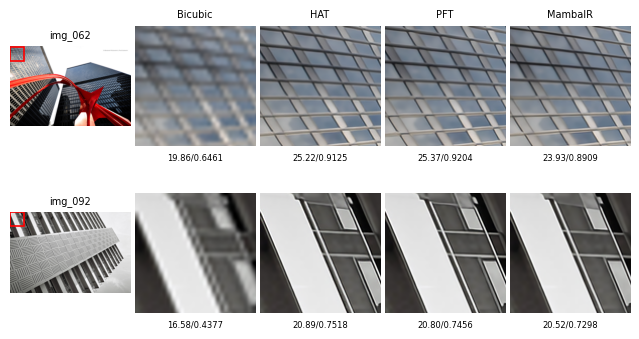

saved /content/sr_experiments/outputs/Images_pdf/fig10_bicubic_comparison.pdf


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def render(rows, names, lr_dir, label_fn, out_pdf, methods_order=None):
    methods = methods_order or list(dict.fromkeys(r['method'] for r in rows))
    ncol = len(methods) + 1
    fig, axes = plt.subplots(len(names), ncol, figsize=(1.6 * ncol, 1.9 * len(names)), squeeze=False)
    for i, n in enumerate(names):
        lr = imread(os.path.join(lr_dir, n + '.png'))
        x, y, w, h = CROPS[n]
        ax = axes[i, 0]; ax.imshow(lr)
        ax.add_patch(Rectangle((x / SCALE, y / SCALE), w / SCALE, h / SCALE, fill=False, ec='red', lw=1.2))
        ax.set_title(n, fontsize=7); ax.axis('off')
        for j, m in enumerate(methods, start=1):
            r = next(r for r in rows if r['image'] == n and r['method'] == m)
            ax = axes[i, j]; ax.imshow(crop(r['sr'], CROPS[n])); ax.axis('off')
            if i == 0: ax.set_title(m, fontsize=7)
            ax.text(0.5, -0.06, label_fn(r), transform=ax.transAxes, ha='center', va='top', fontsize=6)
    plt.subplots_adjust(wspace=0.04, hspace=0.32)
    os.makedirs(os.path.dirname(out_pdf), exist_ok=True)
    fig.savefig(out_pdf, bbox_inches='tight', dpi=300); fig.savefig(out_pdf.replace('.pdf', '.png'), bbox_inches='tight', dpi=200)
    plt.show(); print('saved', out_pdf)

render(fig10_rows, URBAN_IMAGES, U_LR, lambda r: f"{r['psnr']:.2f}/{r['ssim']:.4f}",
       os.path.join(OUT, 'Images_pdf', 'fig10_bicubic_comparison.pdf'))


## 5. FLOPs, latency and peak memory on one GPU

In [ ]:
# Each model is measured in its own process, because MambaIR and PFT ship their own copy of the basicsr package.
EFF_SCRIPT = os.path.join(ROOT, 'measure_efficiency.py')
open(EFF_SCRIPT, 'w').write(r'''
import sys, json, time, importlib, yaml, torch
repo, opt_path, weight, out_json = sys.argv[1:5]
sys.path.insert(0, repo)
for pkg in ('hat', 'basicsr', 'pft', 'mambair'):
    try: importlib.import_module(pkg + '.archs')
    except Exception: pass
from basicsr.utils.registry import ARCH_REGISTRY
cfg = dict(yaml.safe_load(open(opt_path))['network_g']); typ = cfg.pop('type')
net = ARCH_REGISTRY.get(typ)(**cfg)
sd = torch.load(weight, map_location='cpu'); sd = sd.get('params_ema', sd.get('params', sd))
net.load_state_dict(sd, strict=True); dev = 'cuda'; net = net.to(dev).eval()
res = {'type': typ, 'params_M': sum(p.numel() for p in net.parameters()) / 1e6}

# FLOPs at a 1280x640 output (320x160 LR input); fvcore counts one fused multiply-add as one FLOP.
from fvcore.nn import FlopCountAnalysis
def count_flops(h_lr, w_lr, tag):
    # Selective-scan kernels are invisible to fvcore. Add 9*K*N*D per token, the count used in the VMamba/MambaIR code
    # (K scan directions, N state dimension, D inner channels). The scan term is collected in a plain forward pass with
    # hooks (plain Python ints); fvcore then counts everything else without hooks, because under jit tracing shapes
    # are tensors and would make the sum a non-serialisable Tensor.
    scan = {'flops': 0}
    def hook(m, inp, outp):
        x = inp[0]; tokens = int(x.shape[1]) * int(x.shape[2]) if x.dim() == 4 else int(x.shape[1])
        K = int(getattr(m, 'K', 4 if hasattr(m, 'd_inner') else 1))
        scan['flops'] += 9 * K * int(getattr(m, 'd_state')) * int(getattr(m, 'd_inner')) * tokens
    hs = [m.register_forward_hook(hook) for m in net.modules() if hasattr(m, 'd_state') and hasattr(m, 'd_inner')]
    x = torch.rand(1, 3, h_lr, w_lr, device=dev)
    with torch.no_grad(): net(x)
    for h in hs: h.remove()
    with torch.no_grad():
        f = FlopCountAnalysis(net, x); f.unsupported_ops_warnings(False); f.uncalled_modules_warnings(False)
        total = int(f.total())
    res[f'GFLOPs_fvcore_{tag}'] = total / 1e9
    res[f'GFLOPs_selective_scan_{tag}'] = scan['flops'] / 1e9
    res[f'GFLOPs_total_{tag}'] = (total + scan['flops']) / 1e9

count_flops(160, 320, '1280x640')    # 1280x640 output
count_flops(180, 320, '1280x720')    # 1280x720 output, reported as well because published tables often use 720p

# Latency and peak memory at a 512x512 output (128x128 LR input), FP32, batch 1
x = torch.rand(1, 3, 128, 128, device=dev)
with torch.no_grad():
    for _ in range(3): net(x)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    for _ in range(10): net(x)
    torch.cuda.synchronize()
res['latency_ms_512'] = (time.time() - t0) / 10 * 1000
res['peak_mem_GB_512'] = torch.cuda.max_memory_allocated() / 2 ** 30
res['gpu'] = torch.cuda.get_device_name(0)
open(out_json, 'w').write(json.dumps(res, indent=1, default=float)); print(res)
''')

MODELS = {
    'HAT': ('HAT', ['options/test/HAT_SRx4.yml'], WEIGHT_FILES['HAT']),
    'PFT': ('PFT', ['options/test/003_PFT_SRx4_finetune.yml'], WEIGHT_FILES['PFT']),
    'MambaIR': ('MambaIR', ['options/test/mambair/test_MambaIR_SR_x4.yml'], WEIGHT_FILES['MambaIR']),
    'MambaIRv2': ('MambaIR', ['options/test/mambairv2/test_MambaIRv2_SR_x4.yml'], WEIGHT_FILES['MambaIRv2']),
}
eff = {}
if MAMBA_BACKEND == 'reference': os.environ['MAMBA_SHIM_SHAPE_ONLY'] = '1'   # FLOP counting needs shapes only
if DEVICE != 'cuda':
    print('Section 5 needs a CUDA GPU; skipped.')
else:
    for k, (repo, pats, w) in MODELS.items():
        opts = find_file(repo, pats)
        if not opts: print(k, ': option file not found'); continue
        out_json = os.path.join(OUT, f'eff_{k}.json')
        if os.path.exists(out_json): os.remove(out_json)   # never read a stale or half-written file
        r = sh(f'cd {os.path.join(REPOS, repo)} && PYTHONPATH={os.path.join(REPOS, repo)}:{BASICSR} '
               f'{sys.executable} {EFF_SCRIPT} {os.path.join(REPOS, repo)} {opts[0]} {os.path.join(WEIGHTS, w)} {out_json}', check=False)
        try: eff[k] = json.load(open(out_json))
        except Exception as e: print(k, ': no valid result file;', repr(e)[:100])
        if k in eff and MAMBA_BACKEND == 'reference' and k.startswith('Mamba'):
            eff[k]['latency_ms_512'] = eff[k]['peak_mem_GB_512'] = None
            eff[k]['note'] = 'reference selective scan: latency and memory not representative'
os.environ.pop('MAMBA_SHIM_SHAPE_ONLY', None)
print(json.dumps(eff, indent=1))
# Check: compare the HAT and PFT totals with the 1.45T and 1.26T in Table IX at BOTH sizes (640 and 720 rows);
# the size that reproduces them is the one Table IX used, and the MambaIR values must be quoted at that same size.

$ cd /content/sr_experiments/repos/HAT && PYTHONPATH=/content/sr_experiments/repos/HAT:/content/sr_experiments/repos/BasicSR /usr/bin/python3 /content/sr_experiments/measure_efficiency.py /content/sr_experiments/repos/HAT /content/sr_experiments/repos/HAT/options/test/HAT_SRx4.yml /content/sr_experiments/weights/HAT_SRx4.pth /content/sr_experiments/outputs/eff_HAT.json
/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Traceback (most recent call last):
  File "/content/sr_experiments/measure_efficiency.py", line 39, in <module>
 

### Official MambaIR FLOP counter

In [ ]:
flop_script = os.path.join(ROOT, 'mambair_flops.py')
open(flop_script, 'w').write(r'''
import sys, os, torch
repo = sys.argv[1]; sys.path.insert(0, repo); sys.path.insert(0, os.path.join(repo, 'analysis'))
from analysis.model_zoo.mambair import buildMambaIR
from analysis.model_zoo.mambairv2 import buildMambaIRv2Base
from model_zoo.hat import buildHAT
from analysis.utils_fvcore import FLOPs
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
for name, build in [('MambaIR', buildMambaIR), ('MambaIRv2-B', buildMambaIRv2Base), ('HAT', buildHAT)]:
    print('=====', name)
    with torch.no_grad():
        FLOPs.fvcore_flop_count(build(upscale=4).to(dev), input_shape=(3, 640 // 4, 1280 // 4))
''')
if MAMBA_BACKEND == 'reference': os.environ['MAMBA_SHIM_SHAPE_ONLY'] = '1'
r = sh(f'cd {os.path.join(REPOS, "MambaIR")} && PYTHONPATH={os.path.join(REPOS, "MambaIR")} {sys.executable} {flop_script} {os.path.join(REPOS, "MambaIR")}', check=False)
open(os.path.join(OUT, 'mambair_flops_log.txt'), 'w').write((r.stdout or '') + (r.stderr or ''))
os.environ.pop('MAMBA_SHIM_SHAPE_ONLY', None)


$ cd /content/sr_experiments/repos/MambaIR && PYTHONPATH=/content/sr_experiments/repos/MambaIR /usr/bin/python3 /content/sr_experiments/mambair_flops.py /content/sr_experiments/repos/MambaIR
Traceback (most recent call last):
  File "/content/sr_experiments/mambair_flops.py", line 4, in <module>
    from analysis.model_zoo.mambair import buildMambaIR
ModuleNotFoundError: No module named 'analysis.model_zoo.mambair'



'1'

## 6. LaTeX snippets to paste into both manuscripts

In [ ]:
def latex_fig10():
    lines = ['% Whole-image PSNR (dB) / SSIM on Y, bicubic x4, generated by review_experiments.ipynb']
    for n in URBAN_IMAGES:
        vals = ', '.join(f"{r['method']} {r['psnr']:.2f}/{r['ssim']:.4f}" for r in fig10_rows if r['image'] == n)
        lines.append(f'% {n}: {vals}')
    return '\n'.join(lines)

def latex_eff():
    if not eff: return '% efficiency section not run'
    gpu = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'n/a'
    f_ = lambda x, fmt: '--' if x is None else format(x, fmt)
    rows = [f"{k} & {v['params_M']:.1f}M & {v['GFLOPs_total_1280x640']/1000:.2f}T & {f_(v['latency_ms_512'], '.0f')} & {f_(v['peak_mem_GB_512'], '.2f')} \\\\" for k, v in eff.items()]
    gpu = next(iter(eff.values()))['gpu']
    c720 = '% GFLOPs at 1280x720 output: ' + ', '.join(f"{k} {v['GFLOPs_total_1280x720']/1000:.2f}T" for k, v in eff.items() if 'GFLOPs_total_1280x720' in v)
    return ('% Params, FLOPs at 1280x640 output, latency (ms) and peak memory (GB) at 512x512 output on ' + gpu + '\n'
            + '\n'.join(rows) + '\n' + c720)

snip = '\n\n'.join([latex_fig10(), latex_eff()])
open(os.path.join(OUT, 'latex_snippets.tex'), 'w').write(snip); print(snip)
json.dump({'fig10': [{k: v for k, v in r.items() if k != 'sr'} for r in fig10_rows],
           'efficiency': eff},
          open(os.path.join(OUT, 'results.json'), 'w'), indent=1)
print('Upload outputs/Images_pdf/*.pdf to the Overleaf folder Images_pdf/ and send results.json back for the text update.')

% Whole-image PSNR (dB) / SSIM on Y, bicubic x4, generated by review_experiments.ipynb
% img_062: Bicubic 19.86/0.6461, HAT 25.22/0.9125, PFT 25.37/0.9204, MambaIR 23.93/0.8909
% img_092: Bicubic 16.58/0.4377, HAT 20.89/0.7518, PFT 20.80/0.7456, MambaIR 20.52/0.7298

% Params, FLOPs at 1280x640 output, latency (ms) and peak memory (GB) at 512x512 output on NVIDIA L4
PFT & 19.8M & 1.12T & 667 & 1.98 \\
MambaIR & 20.6M & 1.41T & -- & -- \\
MambaIRv2 & 23.1M & 1.70T & -- & -- \\
% GFLOPs at 1280x720 output: PFT 1.35T, MambaIR 1.59T, MambaIRv2 2.04T
Upload outputs/Images_pdf/*.pdf to the Overleaf folder Images_pdf/ and send results.json back for the text update.
